# MLP_JK_05 — Slide context: give the model the whole slide directly

**Why this notebook:** MLP_JK_04's random-neighbor control showed that most of the 3×3 window's **PCC** gain comes from slide-level information: random spots from the same section did nearly as well as the real neighbors. The real neighbors mattered mostly for the **loss**. So here the model gets slide-level context directly, as a **slide average**, alone and together with the 3×3 window.

**Slide average:** for each section, the mean of the raw 4,608-number embeddings of **all** its spots. Every spot on a section gets the same slide average. It is compressed with StandardScaler + PCA 32, fit on the **training sections only** (one row per section, since there are only ~50 training sections). It uses only images, never expression, so a test section can use its own slide average without leakage.

Everything else is the same as MLP_JK_03/04: hidden 128, dropout 0.3, weight decay 1e-3, lr 3e-4, early stopping, shrinkage `k` chosen on validation (4 inner patient groups), retrain on all training patients, 3 model seeds averaged. **Only the input changes.**

| Setup | Input | Size |
|---|---|---|
| **A** | center PCA 256 | 256 |
| **D** | center + 3×3 average PCA 256 | 512 |
| **S** | center + slide average PCA 32 | 288 |
| **DS** | center + 3×3 average + slide average | 544 |

**The questions (decided before running)**
1. Does slide context alone (S) beat the center only (A)? Does it match or beat the 3×3 window (D)?
2. Does combining both (DS) beat D and S? If yes, the local neighbors add something on top of slide context.
3. Does slide context help the error (MSE/NRMSE) or only the ranking (PCC)? Is there any fold where it makes things worse?

A difference only counts if it's larger than the seed spread and holds in most folds. Within-patient PCC can be inflated by section-level information, because each patient has ~3 sections.

**Checks:** ridge raw must reproduce Notebook 5 (0.187); A and D must reproduce MLP_JK_03's A and D, or the notebook stops.

**Reads** `~/JHU/BDD/datasets/BDD_HEST`, Notebook 5's scores, and `~/JHU/BDD/MLP_JK/results/` (MLP_JK_03, MLP_JK_04, MLP_JK_Best).
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_05/` and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `NOTEBOOK_5_DIR`: Notebook 5's saved scores (ridge check).
- `CHECK_DIR`: MLP_JK_03's saved scores. Setups A and D must reproduce them.
- `R1_DIR`: MLP_JK_04's saved scores, for the R1 reference row (random spots from the same section).
- `BEST_DIR`: the current MLP_JK_Best's saved scores, for the best-model check.
- `LOG_RESULTS`: whether this notebook adds its rows to `all_results.csv`.

**Evaluation** (copied from Notebook 5): `N_FOLDS`, `N_GENES`, `MIN_TEST_SD`, `SEED`, and the ridge settings `N_INNER_FOLDS`, `ALPHAS`.

**Inputs**
- `SETUPS`: which setups to run (see the table above).
- `NEIGHBOR_DISTANCE = 1.8` spot spacings = the 3×3 square.
- `N_PCS = 256`: PCA size for the center and the 3×3 average. `SLIDE_PCS = 32`: PCA size for the slide average (it's fit on only ~50 training sections, so it can't have many components).

**MLP** (fixed, the same as MLP_JK_03/04): `HIDDEN_SIZE`, `DROPOUT`, `WEIGHT_DECAY`, `LEARNING_RATE`, `BATCH_SIZE`, `MAX_EPOCHS`, `PATIENCE`, `SHRINK_FACTORS`, `N_VAL_GROUPS`, `N_FINAL_SEEDS`.

**A/D check**: how far A and D may be from MLP_JK_03 before the notebook stops. It's the same pipeline, so they should match closely.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
NOTEBOOK_5_DIR = os.path.expanduser("~/JHU/BDD/Experiments/smoothing_control")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
CHECK_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_03")
R1_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_04")
BEST_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_Best")
NOTEBOOK_NAME = "MLP_JK_05"
LOG_RESULTS = True
OUT_DIR = os.path.join(MLP_DIR, "results", NOTEBOOK_NAME)
RESULTS_LOG = os.path.join(MLP_DIR, "results", "all_results.csv")

N_FOLDS = 4
N_INNER_FOLDS = 3
N_GENES = 50
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

SETUPS = ["A", "D", "S", "DS"]
NEIGHBOR_DISTANCE = 1.8
N_PCS = 256
SLIDE_PCS = 32

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

CHECK_PCC_TOLERANCE = 0.01
CHECK_MSE_TOLERANCE = 0.005

Names and input sizes of the setups, the saved MLP_JK_03 rows that A and D must reproduce, the device (Apple GPU `mps` if available, otherwise CPU), and fixed seeds. The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.

In [3]:
SETUP_NAMES = {
    "A": "A center only",
    "D": "D center + 3x3",
    "S": "S center + slide",
    "DS": "DS center + 3x3 + slide",
}
INPUT_SIZES = {"A": N_PCS, "D": 2 * N_PCS, "S": N_PCS + SLIDE_PCS, "DS": 2 * N_PCS + SLIDE_PCS}
CHECK_NAMES = {"A": "A center only", "D": "D 3x3 average"}
R1_NAME = "MLP_JK_04 R1 (logged)"

RUNS = [{"name": setup, "setup": setup, "draw": None} for setup in SETUPS]

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Real 3×3 neighborhoods (same definition as Notebook 5)

For each section, the spot spacing = median distance from a spot to its closest other spot. A spot's neighborhood = every spot on the same section within 1.8 spacings (the 3×3 square), **including the spot itself**. Edge spots are averaged over what exists.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


real_neighborhoods = find_neighborhoods(NEIGHBOR_DISTANCE)
sizes = np.array([len(n) for n in real_neighborhoods])
print(f"3x3: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, min {sizes.min()}, max {sizes.max()}")

3x3: spots per neighborhood (incl. itself) mean 8.30, min 1, max 10


## Step 3. Patient folds (copied from Notebook 5)

`GroupKFold` puts every spot of a patient in the same fold, so the test patients are never seen in training. Each fold is the test set once.

In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 4. Gene choice and scoring (copied from Notebook 5)

**`choose_genes`**: the 50 genes with the highest variance across the **training** spots of a fold.

**`score_model`** gives two kinds of score for every gene:
- **Pooled**: over all test spots of the fold together. **PCC** = correlation between predicted and true expression. **NRMSE** = prediction error divided by the gene's spread (SD) in the test spots.
- **Within patient**: the same, but inside one test patient at a time, then averaged. This asks whether the model ranks spots correctly *within* a tissue, not just whether it gets the patient's overall level right.

The **mean predictor** predicts the training mean for every spot. Its PCC is undefined (the prediction is constant), and its NRMSE is the bar any useful model should get under.

In [7]:
def choose_genes(train_index):
    Y_train = Y[train_index]
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    mean_of_squares = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel()
    variance = mean_of_squares - mean ** 2
    return np.argsort(variance)[::-1][:N_GENES]


def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)

## Step 5. Ridge on raw embeddings (copied from Notebook 5), and the reproduction check

Inside each fold, using **training spots only**: choose the top-50 genes, fit StandardScaler + PCA 256, choose λ per gene with a 3-group patient split of the training patients, fit ridge, predict the test patients. The mean predictor comes from the same fold (the training mean of each gene).

Then the **check**: the pooled PCC and NRMSE must match Notebook 5's `ridge raw` (0.187 / 1.092). If they don't, the `assert` stops the notebook here, because then the setup isn't the same and nothing below would be comparable.

In [8]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred


def run_ridge_fold(X, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    y_train = Y[train_index][:, gene_index].toarray()
    y_test = Y[test_index][:, gene_index].toarray()

    scaler = StandardScaler(copy=False)
    Z_train = scaler.fit_transform(X[train_index])
    Z_test = scaler.transform(X[test_index])

    pca = PCA(n_components=N_PCS, random_state=SEED, copy=False)
    P_train = pca.fit_transform(Z_train)
    P_test = pca.transform(Z_test)

    alpha_per_gene = choose_alpha_per_gene(P_train, y_train, patient_array[train_index])
    y_pred = fit_and_predict(P_train, y_train, P_test, alpha_per_gene)
    y_mean = np.tile(y_train.mean(axis=0), (len(test_index), 1))

    return {
        "fold": fold,
        "test_index": test_index,
        "genes": all_genes[gene_index],
        "y_test": y_test,
        "y_pred": y_pred,
        "y_mean": y_mean,
        "alpha": alpha_per_gene,
    }


start_time = time.time()
ridge_results = []
for fold in range(N_FOLDS):
    ridge_results.append(run_ridge_fold(X_raw, fold))
    print(f"ridge raw fold {fold} done  ({(time.time() - start_time) / 60:.1f} min)", flush=True)

ridge raw fold 0 done  (0.1 min)


ridge raw fold 1 done  (0.2 min)


ridge raw fold 2 done  (0.3 min)


ridge raw fold 3 done  (0.4 min)


In [9]:
mean_pooled, mean_within = score_model("mean predictor", ridge_results, "y_mean")
ridge_pooled, ridge_within = score_model("ridge raw", ridge_results, "y_pred")

notebook_5_summary = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "summary.csv")).set_index("model")
our_pcc = ridge_pooled["PCC"].mean()
our_nrmse = ridge_pooled["NRMSE"].mean()
notebook_5_pcc = notebook_5_summary.loc["ridge raw", "pooled_PCC"]
notebook_5_nrmse = notebook_5_summary.loc["ridge raw", "pooled_NRMSE"]

print(f"ridge raw, this notebook: pooled PCC {our_pcc:.4f}, NRMSE {our_nrmse:.4f}")
print(f"ridge raw, Notebook 5:    pooled PCC {notebook_5_pcc:.4f}, NRMSE {notebook_5_nrmse:.4f}")

assert abs(our_pcc - notebook_5_pcc) < 0.001 and abs(our_nrmse - notebook_5_nrmse) < 0.001, \
    "Ridge rerun does not reproduce Notebook 5. Stop and find out why before going further."
print("Reproduces Notebook 5.")

ridge raw, this notebook: pooled PCC 0.1868, NRMSE 1.0917
ridge raw, Notebook 5:    pooled PCC 0.1868, NRMSE 1.0917
Reproduces Notebook 5.


## Step 6. The slide average

For every section, the slide average is the plain mean of the raw 4,608-number embeddings of **all** its spots. `slide_means` has one row per section, and `section_number` says which row belongs to each spot, so every spot on a section gets the same slide average.

It's built from images only. No expression is used, so a test section can use its own slide average without any leakage.

In [10]:
section_ids = np.unique(section_array)
section_number = np.searchsorted(section_ids, section_array)
section_patient = np.array([patient_array[section_array == s][0] for s in section_ids])

slide_means = np.zeros((len(section_ids), X_raw.shape[1]), dtype=np.float32)
for i, sample_id in enumerate(section_ids):
    slide_means[i] = X_raw[section_array == sample_id].mean(axis=0)

print(f"Slide averages: {slide_means.shape[0]} sections x {slide_means.shape[1]} numbers")
print(f"Sections per patient: {pd.Series(section_patient).value_counts().value_counts().sort_index().to_dict()}")

Slide averages: 68 sections x 4608 numbers
Sections per patient: {2: 1, 3: 22}


## Step 7. PCA inputs for every fold

In each fold, on the **training patients only**:
- `center`: StandardScaler + PCA 256 of the spots' own embeddings (one row per training spot), as before.
- `mean_3x3`: StandardScaler + PCA 256 of the 3×3 averaged embeddings (one row per training spot), the same as setup D in MLP_JK_03.
- `slide`: StandardScaler + PCA 32 of the slide averages, fit on **one row per training section**. If it were fit on one row per spot, big sections would count more, and the scaler would see the same row hundreds of times.

Each one is then applied to every spot (or every section). The share of variance PCA 32 keeps among the training sections is printed. With only ~50 sections, 32 components keep most of what there is, because 50 points can vary in at most 49 directions.

In [11]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_inputs = [{} for fold in range(N_FOLDS)]
start_time = time.time()

for fold in range(N_FOLDS):
    fold_inputs[fold]["center"] = pca_256(X_raw, fold_train_index[fold])
print(f"Center PCAs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

X_average = neighbor_mean(X_raw, real_neighborhoods)
for fold in range(N_FOLDS):
    fold_inputs[fold]["mean_3x3"] = pca_256(X_average, fold_train_index[fold])
del X_average
print(f"3x3 average PCAs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

for fold in range(N_FOLDS):
    training_patients = np.unique(patient_array[fold_train_index[fold]])
    training_sections = np.where(np.isin(section_patient, training_patients))[0]
    scaler = StandardScaler()
    pca = PCA(n_components=SLIDE_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(slide_means[training_sections]))
    slide_pcs = pca.transform(scaler.transform(slide_means)).astype(np.float32)
    fold_inputs[fold]["slide"] = slide_pcs[section_number]
    print(f"fold {fold}: slide PCA fit on {len(training_sections)} training sections, "
          f"keeps {pca.explained_variance_ratio_.sum():.1%} of their variance")

del X_raw


def build_input(setup, fold, draw=None):
    center = fold_inputs[fold]["center"]
    if setup == "A":
        return center
    if setup == "D":
        return np.concatenate([center, fold_inputs[fold]["mean_3x3"]], axis=1)
    if setup == "S":
        return np.concatenate([center, fold_inputs[fold]["slide"]], axis=1)
    if setup == "DS":
        return np.concatenate([center, fold_inputs[fold]["mean_3x3"], fold_inputs[fold]["slide"]], axis=1)
    raise ValueError(f"unknown setup {setup}")


for setup in SETUPS:
    shape = build_input(setup, 0).shape
    assert shape[1] == INPUT_SIZES[setup]
    print(f"{SETUP_NAMES[setup]:26s}: {shape[0]} spots x {shape[1]} numbers")

Center PCAs done (0.3 min)


3x3 average PCAs done (0.6 min)


fold 0: slide PCA fit on 51 training sections, keeps 98.7% of their variance
fold 1: slide PCA fit on 50 training sections, keeps 98.9% of their variance
fold 2: slide PCA fit on 50 training sections, keeps 98.8% of their variance
fold 3: slide PCA fit on 53 training sections, keeps 98.5% of their variance
A center only             : 30600 spots x 256 numbers
D center + 3x3            : 30600 spots x 512 numbers
S center + slide          : 30600 spots x 288 numbers
DS center + 3x3 + slide   : 30600 spots x 544 numbers


## Step 8. The MLP, training, and shrinkage (copied from MLP_JK_03/04)

**The network**: input → Linear(input, 128) → ReLU → Dropout 0.3 → Linear(128, 50 genes), with no activation at the end (regression).

**`train_mlp`**: Adam (weight decay 1e-3), MSE loss on genes standardized with the training mean and SD, mini-batches of 256. With validation spots, the weights from the best validation epoch are kept, and training stops after `PATIENCE` epochs without improvement. Without validation spots, it trains for a fixed number of epochs.

**`predict`**: dropout off, predictions converted back to log1p units.

**`shrink`**: `train_mean + k × (prediction − train_mean)`. Shrinking doesn't change PCC; it only changes how spread out the predictions are, so `k` is chosen on NRMSE.

In [12]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 9. One run in one fold, start to finish (copied from MLP_JK_03/04)

| Step | Uses |
|---|---|
| Top-50 genes | training spots (chosen once per fold, the same genes for every run and for ridge) |
| PCA inputs | training spots (Step 7) |
| Choose `k` and the number of epochs | 4 validation groups of training patients. Each takes a turn as validation while the MLP trains on the other 3. `k` = lowest validation NRMSE averaged over the 4 groups; epochs = median best epoch |
| Final models | **all** training patients, 3 model seeds (0, 1, 2) |
| Test patients | used once: the 3 seeds' predictions are averaged and shrunk with `k` toward the training mean |

Each model seed's own test predictions are also kept, to measure the seed spread. As before, the test spots' expression is `NaN` in the array the training reads.

In [13]:
fold_genes = []
for fold in range(N_FOLDS):
    fold_genes.append(choose_genes(fold_train_index[fold]))


def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def run_one_fold(run, fold):
    train_index = fold_train_index[fold]
    test_index = np.where(fold_of_spot == fold)[0]
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    P_device = to_device(build_input(run["setup"], fold, run["draw"]))

    val_rows = []
    for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
        fit_mean = y_fold[fit_rows].mean(axis=0)
        val_result = {
            "fold": fold,
            "test_index": val_index,
            "genes": genes,
            "y_test": y_fold[val_index],
            "y_mean": np.tile(fit_mean, (len(val_index), 1)),
            "alpha": no_alpha,
        }
        mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

        trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
        val_pred = predict(trained, P_device, val_index)
        for k in SHRINK_FACTORS:
            val_result["y_pred"] = shrink(val_pred, fit_mean, k)
            scores, _ = score_model("MLP", [val_result], "y_pred")
            val_rows.append({
                "run": run["name"], "setup": run["setup"], "draw": run["draw"],
                "fold": fold, "val_group": group, "k": k,
                "val_PCC": scores["PCC"].mean(),
                "val_NRMSE": scores["NRMSE"].mean(),
                "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                "best_epoch": trained["best_epoch"],
            })

    val_table = pd.DataFrame(val_rows)
    by_k = val_table.groupby("k").agg(
        val_PCC=("val_PCC", "mean"),
        val_NRMSE=("val_NRMSE", "mean"),
        val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
        epochs=("best_epoch", "median"),
    ).reset_index()
    chosen = by_k.loc[by_k["val_NRMSE"].idxmin()].to_dict()
    chosen["passes"] = chosen["val_NRMSE"] <= chosen["val_mean_predictor_NRMSE"]
    n_epochs = max(1, int(round(chosen["epochs"])))

    train_mean = y_fold[train_index].mean(axis=0)
    seed_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        final = train_mlp(P_device, y_fold, train_index, None, n_epochs, SEED + seed_number)
        seed_predictions.append(predict(final, P_device, test_index))
    del P_device

    y_test = Y[test_index][:, gene_index].toarray()
    test_result = {
        "fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
        "y_pred": shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["k"]),
        "alpha": no_alpha,
    }
    seed_results = []
    for prediction in seed_predictions:
        seed_results.append({
            "fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
            "y_pred": shrink(prediction, train_mean, chosen["k"]),
            "alpha": no_alpha,
        })

    chosen.update({"run": run["name"], "setup": run["setup"], "draw": run["draw"],
                   "fold": fold, "final_epochs": n_epochs})
    return test_result, seed_results, val_table, chosen


mlp_results = {}
seed_results = {}
val_tables = []
chosen_rows = []


def run_all_folds(run):
    mlp_results[run["name"]] = []
    seed_results[run["name"]] = [[] for _ in range(N_FINAL_SEEDS)]
    for fold in range(N_FOLDS):
        test_result, fold_seed_results, val_table, chosen = run_one_fold(run, fold)
        mlp_results[run["name"]].append(test_result)
        for seed_number in range(N_FINAL_SEEDS):
            seed_results[run["name"]][seed_number].append(fold_seed_results[seed_number])
        val_tables.append(val_table)
        chosen_rows.append(chosen)
        print(f"{run['name']:12s} fold {fold}: k = {chosen['k']}, {chosen['final_epochs']} epochs  "
              f"({(time.time() - start_time) / 60:.1f} min)", flush=True)
    if device.type == "mps":
        torch.mps.empty_cache()

## Step 10. Test MSE, and the saved rows to compare with

**Test MSE** (the loss): the average squared difference between predicted and true log1p expression, per gene over all test spots of a fold, then averaged over genes and folds. Each gene's `MSE = (NRMSE × test SD)²`.

**Saved rows**
- MLP_JK_03's A and D: setups A and D here must reproduce them (Step 11). The genes are checked to be the same in every fold.
- MLP_JK_04's R1 (random spots from the same section, averaged over 3 draws): a reference row. It's read from MLP_JK_04's summary and per-fold scores.
- The current MLP_JK_Best: its validation PCC is what a setup here must beat (Step 15).

In [14]:
test_sd_rows = []
for fold in range(N_FOLDS):
    test_index = np.where(fold_of_spot == fold)[0]
    y_test = Y[test_index][:, fold_genes[fold]].toarray()
    for g, gene in enumerate(all_genes[fold_genes[fold]]):
        test_sd_rows.append({"fold": fold, "gene": gene, "test_SD": np.std(y_test[:, g])})
test_sd = pd.DataFrame(test_sd_rows)


def add_mse(pooled_table):
    table = pooled_table.drop(columns=["test_SD", "MSE"], errors="ignore")
    table = table.merge(test_sd, on=["fold", "gene"], how="left")
    table["MSE"] = (table["NRMSE"] * table["test_SD"]) ** 2
    return table


check_pooled = pd.read_csv(os.path.join(CHECK_DIR, "pooled_gene_scores.csv"))
check_scores = {}
for setup, saved_name in CHECK_NAMES.items():
    p = check_pooled[check_pooled["model"] == saved_name]
    for fold in range(N_FOLDS):
        assert set(p.loc[p["fold"] == fold, "gene"]) == set(all_genes[fold_genes[fold]]), \
            f"MLP_JK_03 {saved_name}, fold {fold}: genes differ"
    p = add_mse(p)
    check_scores[setup] = {"MSE": p["MSE"].mean(), "PCC": p["PCC"].mean()}
    print(f"MLP_JK_03 {saved_name}: test MSE {check_scores[setup]['MSE']:.4f}, pooled PCC {check_scores[setup]['PCC']:.4f}")

r1_summary = pd.read_csv(os.path.join(R1_DIR, "summary.csv")).set_index("model").loc["R1 random same section"]
r1_folds = pd.read_csv(os.path.join(R1_DIR, "fold_scores.csv"))
r1_folds = r1_folds[r1_folds["model"] == "R1 random same section"].copy()
r1_folds["model"] = R1_NAME
print(f"{R1_NAME}: test MSE {r1_summary['test_MSE']:.4f}, pooled PCC {r1_summary['pooled_PCC']:.4f}")

best_summary = pd.read_csv(os.path.join(BEST_DIR, "summary.csv"))
best_row = best_summary[best_summary["val_PCC"].notna() & ~best_summary["model"].str.contains("logged")].iloc[0]
best_val_PCC = best_row["val_PCC"]
print(f"Current MLP_JK_Best ({best_row['model']}): validation PCC {best_val_PCC:.4f}")

MLP_JK_03 A center only: test MSE 0.9728, pooled PCC 0.1767
MLP_JK_03 D 3x3 average: test MSE 0.9584, pooled PCC 0.2064
MLP_JK_04 R1 (logged): test MSE 0.9698, pooled PCC 0.2022
Current MLP_JK_Best (E 5x5 average): validation PCC 0.2256


## Step 11. Run A and D first, and check them against MLP_JK_03

A and D are exactly MLP_JK_03's setups A and D (same inputs, settings and seeds), so they should reproduce them closely. If either one's pooled PCC is more than 0.01 away, or its test MSE more than 0.005 away, the notebook stops: the pipeline would differ from MLP_JK_03, and S and DS wouldn't be comparable.

In [15]:
start_time = time.time()
for setup in ["A", "D"]:
    run_all_folds({"name": setup, "setup": setup, "draw": None})
    p, _ = score_model(setup, mlp_results[setup], "y_pred")
    p = add_mse(p)
    print(f"\nSetup {setup} here:      test MSE {p['MSE'].mean():.4f}, pooled PCC {p['PCC'].mean():.4f}")
    print(f"MLP_JK_03 setup {setup}: test MSE {check_scores[setup]['MSE']:.4f}, pooled PCC {check_scores[setup]['PCC']:.4f}\n")
    assert abs(p["PCC"].mean() - check_scores[setup]["PCC"]) <= CHECK_PCC_TOLERANCE, \
        f"Setup {setup}'s PCC is far from MLP_JK_03. Stop and check before going further."
    assert abs(p["MSE"].mean() - check_scores[setup]["MSE"]) <= CHECK_MSE_TOLERANCE, \
        f"Setup {setup}'s test MSE is far from MLP_JK_03. Stop and check before going further."
print("A and D reproduce MLP_JK_03.")

A            fold 0: k = 0.4, 17 epochs  (0.2 min)


A            fold 1: k = 0.4, 8 epochs  (0.3 min)


A            fold 2: k = 0.4, 14 epochs  (0.5 min)


A            fold 3: k = 0.4, 10 epochs  (0.7 min)



Setup A here:      test MSE 0.9728, pooled PCC 0.1767
MLP_JK_03 setup A: test MSE 0.9728, pooled PCC 0.1767



D            fold 0: k = 0.4, 10 epochs  (0.8 min)


D            fold 1: k = 0.4, 10 epochs  (1.0 min)


D            fold 2: k = 0.4, 9 epochs  (1.1 min)


D            fold 3: k = 0.4, 10 epochs  (1.3 min)



Setup D here:      test MSE 0.9584, pooled PCC 0.2064
MLP_JK_03 setup D: test MSE 0.9584, pooled PCC 0.2064

A and D reproduce MLP_JK_03.


## Step 12. Run S and DS

In [16]:
for run in RUNS:
    if run["setup"] not in ["A", "D"]:
        run_all_folds(run)

val_scores = pd.concat(val_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)
print("All runs done.")

S            fold 0: k = 0.4, 18 epochs  (1.5 min)


S            fold 1: k = 0.2, 12 epochs  (1.7 min)


S            fold 2: k = 0.2, 14 epochs  (1.9 min)


S            fold 3: k = 0.2, 14 epochs  (2.0 min)


DS           fold 0: k = 0.2, 12 epochs  (2.2 min)


DS           fold 1: k = 0.2, 4 epochs  (2.3 min)


DS           fold 2: k = 0.2, 11 epochs  (2.5 min)


DS           fold 3: k = 0.2, 14 epochs  (2.7 min)


All runs done.


## Step 13. Results

**Chosen `k` and epochs per setup and fold.** Chosen on validation patients only. `val_PCC` and `val_NRMSE` are averaged over the 4 validation groups; `passes` = validation NRMSE no worse than the mean predictor's.

In [17]:
pd.set_option("display.width", 250)
columns = ["run", "fold", "k", "final_epochs", "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE", "passes"]
print(chosen_settings[columns].round(4).to_string(index=False))

run  fold   k  final_epochs  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes
  A     0 0.4            17   0.2337     1.1138                    1.1430    True
  A     1 0.4             8   0.1494     1.1154                    1.1307    True
  A     2 0.4            14   0.1810     1.0703                    1.0955    True
  A     3 0.4            10   0.1952     1.0698                    1.0824    True
  D     0 0.4            10   0.2518     1.1087                    1.1430    True
  D     1 0.4            10   0.1669     1.1137                    1.1307    True
  D     2 0.4             9   0.1855     1.0681                    1.0955    True
  D     3 0.4            10   0.2261     1.0647                    1.0824    True
  S     0 0.4            18   0.2469     1.1086                    1.1430    True
  S     1 0.2            12   0.1543     1.1174                    1.1307    True
  S     2 0.2            14   0.1805     1.0779                    1.0955    True
  S     3 0.2   

**Results table** (test patients, 4 folds). Test MSE and NRMSE: lower is better. Pooled and within-patient PCC: higher is better. `seed_MSE_range` / `seed_PCC_range` are the spread across the 3 model seeds (lowest to highest). A difference between two setups smaller than these could be luck. `chosen_k` lists the `k` of folds 0–3.

Remember that within-patient PCC can be raised by section-level information: each patient has ~3 sections, so getting the differences *between* a patient's sections right also counts.

In [18]:
pooled_tables = [add_mse(mean_pooled), add_mse(ridge_pooled)]
within_tables = [mean_within, ridge_within]
summary_rows = []
for model_name, p, w in [("mean predictor", pooled_tables[0], mean_within), ("ridge raw", pooled_tables[1], ridge_within)]:
    summary_rows.append({
        "model": model_name,
        "input_size": N_PCS if model_name == "ridge raw" else np.nan,
        "test_MSE": p["MSE"].mean(),
        "pooled_PCC": p["PCC"].mean(),
        "within_PCC": w["PCC_within"].mean(),
        "NRMSE": p["NRMSE"].mean(),
    })
summary_rows.append({
    "model": R1_NAME,
    "input_size": r1_summary["input_size"],
    "test_MSE": r1_summary["test_MSE"],
    "pooled_PCC": r1_summary["pooled_PCC"],
    "within_PCC": r1_summary["within_PCC"],
    "NRMSE": r1_summary["NRMSE"],
    "val_PCC": r1_summary["val_PCC"],
    "val_NRMSE": r1_summary["val_NRMSE"],
    "chosen_k": r1_summary["chosen_k"],
})

for run in RUNS:
    p, w = score_model(SETUP_NAMES[run["setup"]], mlp_results[run["name"]], "y_pred")
    p = add_mse(p)
    pooled_tables.append(p)
    within_tables.append(w)

    seed_mse = []
    seed_pcc = []
    for seed_number in range(N_FINAL_SEEDS):
        seed_pooled, _ = score_model("seed", seed_results[run["name"]][seed_number], "y_pred")
        seed_pooled = add_mse(seed_pooled)
        seed_mse.append(seed_pooled["MSE"].mean())
        seed_pcc.append(seed_pooled["PCC"].mean())

    c = chosen_settings[chosen_settings["run"] == run["name"]].sort_values("fold")
    summary_rows.append({
        "model": SETUP_NAMES[run["setup"]],
        "input_size": INPUT_SIZES[run["setup"]],
        "test_MSE": p["MSE"].mean(),
        "pooled_PCC": p["PCC"].mean(),
        "within_PCC": w["PCC_within"].mean(),
        "NRMSE": p["NRMSE"].mean(),
        "val_PCC": c["val_PCC"].mean(),
        "val_NRMSE": c["val_NRMSE"].mean(),
        "val_mean_predictor_NRMSE": c["val_mean_predictor_NRMSE"].mean(),
        "chosen_k": "/".join(str(k) for k in c["k"]),
        "seed_MSE_range": max(seed_mse) - min(seed_mse),
        "seed_PCC_range": max(seed_pcc) - min(seed_pcc),
    })

pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)
summary = pd.DataFrame(summary_rows)
setup_names = [SETUP_NAMES[s] for s in SETUPS]
model_order = ["mean predictor", "ridge raw", R1_NAME] + setup_names
columns = ["model", "input_size", "test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "val_PCC", "val_NRMSE",
           "chosen_k", "seed_MSE_range", "seed_PCC_range"]
print(summary[columns].round(4).to_string(index=False))
mean_predictor_nrmse = summary.loc[summary["model"] == "mean predictor", "NRMSE"].iloc[0]

                  model  input_size  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE                                            chosen_k  seed_MSE_range  seed_PCC_range
         mean predictor         NaN    1.0092         NaN         NaN 1.0997      NaN        NaN                                                 NaN             NaN             NaN
              ridge raw       256.0    0.9837      0.1868      0.1514 1.0917      NaN        NaN                                                 NaN             NaN             NaN
  MLP_JK_04 R1 (logged)       512.0    0.9698      0.2022      0.1712 1.0795   0.2209     1.0885 0.4/0.2/0.4/0.2 | 0.4/0.2/0.4/0.4 | 0.4/0.2/0.4/0.4             NaN             NaN
          A center only       256.0    0.9728      0.1767      0.1433 1.0806   0.1898     1.0923                                     0.4/0.4/0.4/0.4          0.0035          0.0056
         D center + 3x3       512.0    0.9584      0.2064      0.1584 1.0709   0.2076     1.088

**Per-fold tables.** Each fold has different test patients, so what matters is whether one setup beats another in most folds. The MLP_JK_04 R1 row is shown for comparison.

In [19]:
fold_scores = pooled.groupby(["model", "fold"]).agg(MSE=("MSE", "mean"), PCC=("PCC", "mean"), NRMSE=("NRMSE", "mean")).reset_index()
within_fold = within.groupby(["model", "fold"])["PCC_within"].mean().reset_index()
fold_scores = fold_scores.merge(within_fold, on=["model", "fold"], how="left")
fold_scores = pd.concat([fold_scores, r1_folds[["model", "fold", "MSE", "PCC", "NRMSE", "PCC_within"]]], ignore_index=True)

for column, title in [("MSE", "Test MSE"), ("PCC", "Pooled PCC"), ("NRMSE", "Pooled NRMSE"), ("PCC_within", "Within-patient PCC")]:
    print(f"{title} per fold:")
    print(fold_scores.pivot(index="model", columns="fold", values=column).reindex(model_order).round(4).to_string())
    print()

Test MSE per fold:
fold                          0       1       2       3
model                                                  
mean predictor           1.0422  1.1320  0.9242  0.9386
ridge raw                1.0687  1.0381  0.9487  0.8792
MLP_JK_04 R1 (logged)    1.0235  1.0769  0.8886  0.8904
A center only            1.0299  1.0501  0.9086  0.9026
D center + 3x3           1.0137  1.0406  0.8891  0.8904
S center + slide         1.0473  1.0625  0.8911  0.8879
DS center + 3x3 + slide  1.0271  1.0648  0.8862  0.8879

Pooled PCC per fold:
fold                          0       1       2       3
model                                                  
mean predictor              NaN     NaN     NaN     NaN
ridge raw                0.1576  0.3129  0.0903  0.1864
MLP_JK_04 R1 (logged)    0.1761  0.3474  0.1194  0.1658
A center only            0.1565  0.3088  0.1018  0.1397
D center + 3x3           0.2084  0.3238  0.1274  0.1661
S center + slide         0.1482  0.3620  0.1601  0.2522
DS cent

**Fold-by-fold differences.** For MSE and NRMSE, negative means the first setup has the lower (better) error. For PCC, positive means the first setup is better. Each line also counts the folds where the first setup is better, and compares the average difference with the larger seed spread of the two setups.

In [20]:
pcc_table = fold_scores.pivot(index="model", columns="fold", values="PCC")
mse_table = fold_scores.pivot(index="model", columns="fold", values="MSE")
nrmse_table = fold_scores.pivot(index="model", columns="fold", values="NRMSE")
seed_mse_range = summary.set_index("model")["seed_MSE_range"]
seed_pcc_range = summary.set_index("model")["seed_PCC_range"]

comparison_rows = []
for first, second in [("S", "A"), ("S", "D"), ("DS", "D"), ("DS", "S")]:
    a = SETUP_NAMES[first]
    b = SETUP_NAMES[second]
    mse_difference = mse_table.loc[a] - mse_table.loc[b]
    nrmse_difference = nrmse_table.loc[a] - nrmse_table.loc[b]
    pcc_difference = pcc_table.loc[a] - pcc_table.loc[b]
    mse_spread = max(seed_mse_range[a], seed_mse_range[b])
    pcc_spread = max(seed_pcc_range[a], seed_pcc_range[b])
    print(f"{first:2s} - {second:2s}:  MSE " + " ".join(f"{d:+.4f}" for d in mse_difference)
          + f"  (mean {mse_difference.mean():+.4f}, {first} lower in {(mse_difference < 0).sum()}/4, seed spread {mse_spread:.4f})")
    print(f"           NRMSE " + " ".join(f"{d:+.4f}" for d in nrmse_difference)
          + f"  (mean {nrmse_difference.mean():+.4f}, {first} lower in {(nrmse_difference < 0).sum()}/4)")
    print(f"           PCC " + " ".join(f"{d:+.3f}" for d in pcc_difference)
          + f"    (mean {pcc_difference.mean():+.4f}, {first} higher in {(pcc_difference > 0).sum()}/4, seed spread {pcc_spread:.4f})\n")
    comparison_rows.append({
        "comparison": f"{first} - {second}",
        "MSE_difference": mse_difference.mean(), "MSE_folds_better": int((mse_difference < 0).sum()), "MSE_seed_spread": mse_spread,
        "NRMSE_difference": nrmse_difference.mean(), "NRMSE_folds_better": int((nrmse_difference < 0).sum()),
        "PCC_difference": pcc_difference.mean(), "PCC_folds_better": int((pcc_difference > 0).sum()), "PCC_seed_spread": pcc_spread,
    })
comparisons = pd.DataFrame(comparison_rows)

S  - A :  MSE +0.0173 +0.0124 -0.0175 -0.0148  (mean -0.0006, S lower in 2/4, seed spread 0.0036)
           NRMSE +0.0078 +0.0119 -0.0143 -0.0087  (mean -0.0008, S lower in 2/4)
           PCC -0.008 +0.053 +0.058 +0.112    (mean +0.0539, S higher in 3/4, seed spread 0.0056)

S  - D :  MSE +0.0336 +0.0219 +0.0021 -0.0025  (mean +0.0138, S lower in 1/4, seed spread 0.0036)
           NRMSE +0.0149 +0.0255 -0.0043 -0.0007  (mean +0.0088, S lower in 2/4)
           PCC -0.060 +0.038 +0.033 +0.086    (mean +0.0242, S higher in 3/4, seed spread 0.0055)

DS - D :  MSE +0.0134 +0.0242 -0.0029 -0.0025  (mean +0.0081, DS lower in 2/4, seed spread 0.0054)
           NRMSE +0.0058 +0.0240 -0.0071 -0.0013  (mean +0.0053, DS lower in 2/4)
           PCC -0.024 +0.028 +0.060 +0.064    (mean +0.0321, DS higher in 3/4, seed spread 0.0110)

DS - S :  MSE -0.0201 +0.0023 -0.0049 +0.0001  (mean -0.0057, DS lower in 2/4, seed spread 0.0054)
           NRMSE -0.0091 -0.0015 -0.0028 -0.0006  (mean -0.0035,

## Step 14. Plot

**Test MSE and pooled PCC per setup.** Bars are the average over folds; dots are the 4 folds. The black line on the setups shows the range over the 3 model seeds. The dashed line is the mean predictor's MSE.

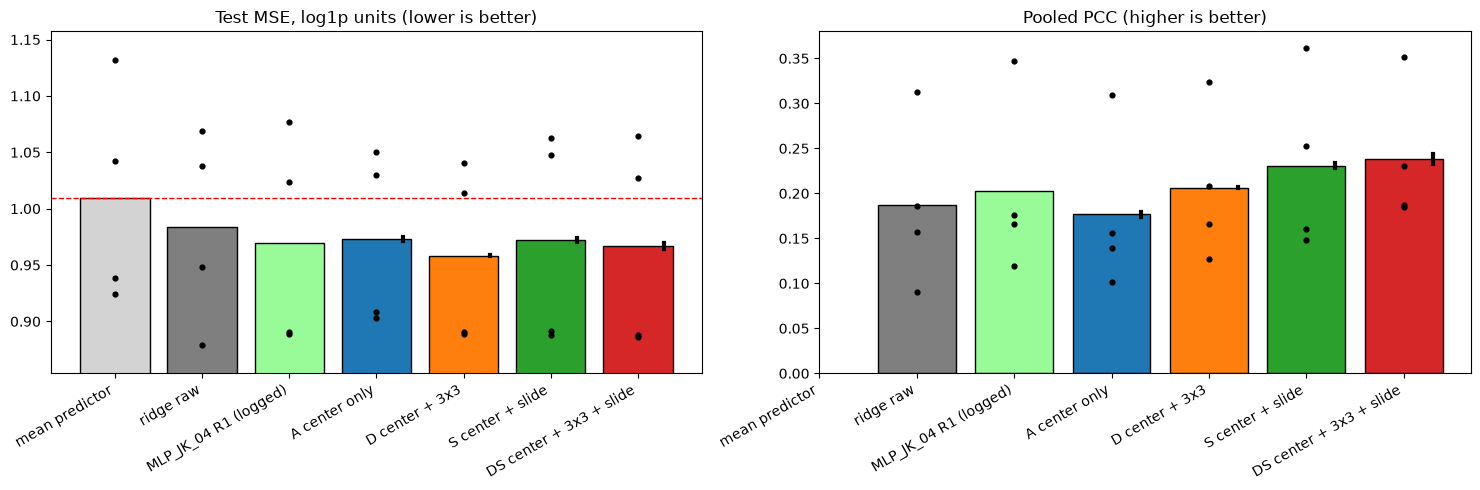

In [21]:
colors = {
    "mean predictor": "lightgrey",
    "ridge raw": "tab:gray",
    R1_NAME: "palegreen",
    SETUP_NAMES["A"]: "tab:blue",
    SETUP_NAMES["D"]: "tab:orange",
    SETUP_NAMES["S"]: "tab:green",
    SETUP_NAMES["DS"]: "tab:red",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(model_order))
for ax, column, summary_column, label in [(axes[0], "MSE", "test_MSE", "MSE"), (axes[1], "PCC", "pooled_PCC", "PCC")]:
    for i, model_name in enumerate(model_order):
        values = fold_scores.loc[fold_scores["model"] == model_name, column]
        if values.notna().any():
            ax.bar(i, values.mean(), color=colors[model_name], edgecolor="black")
            ax.scatter(np.full(len(values), i), values, color="black", s=12, zorder=3)
        if model_name in setup_names:
            row = summary[summary["model"] == model_name].iloc[0]
            half = row[f"seed_{label}_range"] / 2
            ax.plot([i + 0.3, i + 0.3], [row[summary_column] - half, row[summary_column] + half], color="black", linewidth=3)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=30, ha="right")
axes[0].set_title("Test MSE, log1p units (lower is better)")
axes[1].set_title("Pooled PCC (higher is better)")
mean_mse = summary.loc[summary["model"] == "mean predictor", "test_MSE"].iloc[0]
axes[0].axhline(mean_mse, color="red", linestyle="--", linewidth=1)
low = fold_scores["MSE"].min()
high = fold_scores["MSE"].max()
axes[0].set_ylim(low - 0.1 * (high - low), high + 0.1 * (high - low))
plt.tight_layout()
save_figure("1_mse_and_pcc.png")
plt.show()

## Step 15. Does any setup beat MLP_JK_Best?

The rule: a setup replaces MLP_JK_Best only if its **validation PCC is higher** than the current best's and its validation NRMSE is no worse than the mean predictor's. Test scores are not used.

In [22]:
best_rows = []
for setup in SETUPS:
    row = summary[summary["model"] == SETUP_NAMES[setup]].iloc[0]
    passes = row["val_NRMSE"] <= row["val_mean_predictor_NRMSE"]
    best_rows.append({
        "setup": setup,
        "val_PCC": row["val_PCC"],
        "val_NRMSE": row["val_NRMSE"],
        "val_mean_predictor_NRMSE": row["val_mean_predictor_NRMSE"],
        "passes_NRMSE_rule": passes,
        "beats_best": passes and row["val_PCC"] > best_val_PCC,
    })
best_check = pd.DataFrame(best_rows)
print(f"Current MLP_JK_Best validation PCC: {best_val_PCC:.4f}\n")
print(best_check.round(4).to_string(index=False))

winners = best_check[best_check["beats_best"]]
if len(winners) == 0:
    new_best_setup = None
    print("\nNo setup beats MLP_JK_Best. It stays as it is.")
else:
    new_best_setup = winners.sort_values("val_PCC", ascending=False).iloc[0]["setup"]
    print(f"\nSetup {new_best_setup} beats MLP_JK_Best on validation and should replace it.")

Current MLP_JK_Best validation PCC: 0.2256

setup  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes_NRMSE_rule  beats_best
    A   0.1898     1.0923                    1.1129               True       False
    D   0.2076     1.0888                    1.1129               True       False
    S   0.1992     1.0939                    1.1129               True       False
   DS   0.2086     1.0947                    1.1129               True       False

No setup beats MLP_JK_Best. It stays as it is.


## Step 16. Save results and add them to the log

`all_results.csv` gets one row each for the mean predictor, ridge raw, A, D, S and DS. The MLP_JK_04 R1 reference row isn't added again. If this notebook is run again, its old rows are replaced instead of duplicated.

In [23]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
comparisons.to_csv(os.path.join(OUT_DIR, "comparisons.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)
best_check.to_csv(os.path.join(OUT_DIR, "best_check.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "setups": SETUPS,
    "setup_names": SETUP_NAMES,
    "input_sizes": INPUT_SIZES,
    "new_best_setup": new_best_setup,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_pcs": N_PCS,
    "slide_pcs": SLIDE_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "n_genes": N_GENES,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        if row["model"] == R1_NAME:
            continue
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": row["model"],
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["NRMSE"],
            "mean_predictor_NRMSE": mean_predictor_nrmse,
            "val_PCC": row.get("val_PCC", np.nan),
            "val_NRMSE": row.get("val_NRMSE", np.nan),
            "date": today,
        })
    new_rows = pd.DataFrame(log_rows)
    if os.path.exists(RESULTS_LOG):
        old_rows = pd.read_csv(RESULTS_LOG)
        old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
        new_rows = pd.concat([old_rows, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_LOG, index=False)
    print(new_rows.tail(8).round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

 notebook                condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date
MLP_JK_04   R1 random same section      0.2022              0.1712 1.0795                1.0997   0.2209     1.0885 2026-11-14
MLP_JK_04 R2 random other patients      0.1737              0.1407 1.0834                1.0997   0.1818     1.0947 2026-11-14
MLP_JK_05           mean predictor         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-14
MLP_JK_05                ridge raw      0.1868              0.1514 1.0917                1.0997      NaN        NaN 2026-11-14
MLP_JK_05            A center only      0.1767              0.1433 1.0806                1.0997   0.1898     1.0923 2026-11-14
MLP_JK_05           D center + 3x3      0.2064              0.1584 1.0709                1.0997   0.2076     1.0888 2026-11-14
MLP_JK_05         S center + slide      0.2306              0.1968 1.0798                1.0997   0.1992     1.

## Summary in plain words: does slide context help?

**Checks first**
- Ridge on raw embeddings reproduced Notebook 5 (pooled PCC 0.1868).
- Setups A and D reproduced MLP_JK_03 exactly (A: MSE 0.9728, PCC 0.1767; D: MSE 0.9584, PCC 0.2064).
- The slide PCA (32 components, fit on 50–53 training sections) kept 98.5–98.9% of the training sections' variance.

### What each score means

| Score | What it means | Good vs. bad |
|---|---|---|
| **Test MSE** (the loss) | Average squared difference between predicted and true expression (log1p), over all test spots and the 50 genes | Lower is better. Mean predictor = 1.009 |
| **NRMSE** | The error divided by the gene's spread | Lower is better; below the mean predictor (1.100) = better than guessing the average |
| **Pooled PCC** | Correlation between predicted and true expression over all test spots, across patients and sections | 0 = no relation, 1 = perfect. It rewards getting differences **between** patients and sections right, as well as between spots |
| **Within-patient PCC** | The same correlation inside one patient at a time | Higher is better. Each patient has ~3 sections, so getting the differences *between those sections* right also counts. That means it can be inflated by section-level information |
| **Validation PCC / NRMSE** | The same scores on held-out *training* patients. The only scores used for choosing | Higher PCC, lower NRMSE |
| **Seed spread** | How much a score moves between the 3 model seeds | A difference smaller than this could be luck |

A difference is called **real** here only if it is bigger than the seed spread **and** holds in at least 3 of 4 folds.

### What we got

| Setup | Size | Test MSE | Pooled PCC | Within-patient PCC | NRMSE | Validation PCC | Validation NRMSE | k | Seed spread (MSE / PCC) |
|---|---|---|---|---|---|---|---|---|---|
| mean predictor | — | 1.009 | — | — | 1.100 | — | — | — | — |
| ridge raw | 256 | 0.984 | 0.187 | 0.151 | 1.092 | — | — | — | — |
| MLP_JK_04 R1 (random same section) | 512 | 0.970 | 0.202 | 0.171 | 1.080 | 0.221 | 1.089 | mixed | — |
| **A** center only | 256 | 0.973 | 0.177 | 0.143 | 1.081 | 0.190 | 1.092 | 0.4 ×4 | 0.004 / 0.006 |
| **D** center + 3×3 | 512 | **0.958** | 0.206 | 0.158 | **1.071** | 0.208 | **1.089** | 0.4 ×4 | 0.002 / 0.001 |
| **S** center + slide | 288 | 0.972 | 0.231 | **0.197** | 1.080 | 0.199 | 1.094 | 0.4/0.2/0.2/0.2 | 0.004 / 0.006 |
| **DS** center + 3×3 + slide | 544 | 0.967 | **0.239** | 0.192 | 1.076 | **0.209** | 1.095 | 0.2 ×4 | 0.005 / 0.011 |

### The three questions

**1. Does slide context alone (S) beat the center only (A)? Does it match or beat the 3×3 window (D)?**
- **S vs. A, ranking: yes.** Pooled PCC +0.054, about 10 times the seed spread, higher in 3 of 4 folds (fold 0 is slightly lower, −0.008).
- **S vs. A, error: no.** Test MSE is the same (−0.0006, lower in only 2 of 4 folds).
- **S vs. D: mixed.** S ranks better (pooled PCC +0.024, higher in 3 of 4 folds, bigger than the seed spread), but its error is clearly worse: test MSE +0.014 (worse in folds 0 and 1, tied in folds 2 and 3) and NRMSE +0.009. S beats D on ranking, not on error.

**2. Does combining both (DS) beat D and S?**
- **DS vs. D:** better ranking (pooled PCC +0.032, higher in 3 of 4 folds, bigger than the seed spread), but **higher** error (test MSE +0.008, worse in folds 0 and 1). Adding slide context to the 3×3 window trades accuracy for ranking.
- **DS vs. S:** this is the "do the local neighbors add something on top of slide context?" test. Pooled PCC +0.008 (higher in 2 of 4 folds, smaller than DS's seed spread of 0.011): **not real**. Test MSE −0.006 (lower in only 2 of 4 folds): **not real**. NRMSE is lower in all 4 folds, but only by 0.0035. So on top of slide context, the local neighbors add at most a small reduction in error.

**3. Does slide context help the error or only the ranking?**
**Only the ranking.**
- It raises pooled PCC a lot. DS's 0.239 is the highest test pooled PCC of any model so far.
- It doesn't lower test MSE or NRMSE. Against A, the error is unchanged; against D, the error gets worse.
- **Folds where it makes things worse:** in **fold 0**, slide context lowers PCC *and* raises MSE (S vs. A: MSE +0.017, PCC −0.008; DS vs. D: MSE +0.013, PCC −0.024). In **fold 1**, PCC goes up but MSE also goes up (S vs. A: +0.012; DS vs. D: +0.024). Better ranking with a worse error is the sign of predictions that are in the right order but shifted to the wrong level for whole sections.
- The shrinkage agrees: with slide context, most folds chose the strongest shrinkage (`k` = 0.2) instead of 0.4, which means the model's raw predictions were less trustworthy.

**About within-patient PCC:** S and DS have the highest within-patient PCC so far (0.197 and 0.192). But each patient has ~3 sections, and a slide average is exactly the kind of input that gets the differences *between* a patient's sections right. So this gain is probably section-level, not better ranking of spots within one tissue, and it shouldn't be read as "S ranks spots within a tissue better."

**Validation doesn't confirm the PCC gain.** On validation patients, S (0.199) is only slightly above A (0.190) and below D (0.208), and DS (0.209) is about the same as D. The large test PCC gain shows up only on the test folds. That makes it less certain: with only ~4 patients per validation group, a slide-level signal may help some groups of patients and not others.

### Bottom line
Slide-level context helps the model **rank** spots across patients and sections (pooled PCC up to 0.239), but it doesn't make the predicted **values** more accurate. For the error, the real 3×3 neighborhood (D) is still the best input. In two of four folds, slide context makes the error worse. Combined with MLP_JK_04, the picture is consistent: slide-level information drives the ranking gains, and local neighbors drive the accuracy gains.

### Best model
No setup beats MLP_JK_Best (setup E, validation PCC 0.226) by the rule: the best here is DS at 0.209. MLP_JK_Best is unchanged. DS's high **test** PCC is not used to choose, by design.